**About:** every annotated cell division, on the image, next to what the pipeline predicted.

Duplicated from `TrackingInf.ipynb`. That notebook runs the model on one sample;
this one reads the *already post-processed* graphs and asks a narrower question —
where are the 151 annotated divisions, did the chain recover each one, and what
does the failure look like in the raw volume.

Why it exists: the division term is `0.1 * division_jaccard` of the score, the
chain currently converts about one in seven, and every attempt to improve that
from geometry alone has failed (`src/postprocessing/README_edge.md`, "Divisions").
The numbers say precision is the binding constraint; these are the pictures
behind the numbers.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
cd ../src

/data/kaggle-cell-tracking/src


In [3]:
import json
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import zarr
import tracksdata as td
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

from utils.plot import scatter_by_depth

warnings.filterwarnings("ignore", category=UserWarning)

In [4]:
from params import TRAIN_DIR, SCALE

TRAIN_DIR = Path(TRAIN_DIR)
SC = np.asarray(SCALE)          # um per voxel, (z, y, x)

# The post-processed graphs to judge. Any `<preds>_pp` folder written by
# main_edge_postprocess.py works; this is the fold-0+1 out-of-fold run the
# division stage was tuned on (cv_score 0.8437).
PP_DIR = Path("../logs/edge_run/2026-09-08/13/preds_0.50_pp")

# The metric's matching radius. A prediction further than this from an
# annotated cell is not that cell, so nothing here should use a looser one.
MATCH_UM = 7.0

print("post-processed graphs :", PP_DIR.resolve())
print("stacks                :", len(list(PP_DIR.glob("*.npz"))))

post-processed graphs : /data/kaggle-cell-tracking/logs/edge_run/2026-09-08/13/preds_0.50_pp
stacks                : 199


### Every annotated division

In [5]:
def gt_divisions(stem):
    """Every annotated dividing cell in one stack, with its two daughters.

    A division is a ground-truth node of out-degree >= 2. Positions stay in
    voxels, as the volume indexes them; `sister_um` is physical.
    """
    g = td.graph.IndexedRXGraph.from_geff(TRAIN_DIR / f"{stem}.geff")
    g = g[0] if isinstance(g, tuple) else g
    nodes = {int(r["node_id"]): r for r in g.node_attrs().iter_rows(named=True)}
    kids = {}
    for e in g.edge_attrs().iter_rows(named=True):
        kids.setdefault(int(e["source_id"]), []).append(int(e["target_id"]))

    zyx = lambda n: np.array([nodes[n]["z"], nodes[n]["y"], nodes[n]["x"]], float)
    out = []
    for parent, children in kids.items():
        if len(children) < 2:
            continue
        c1, c2 = zyx(children[0]), zyx(children[1])
        out.append(dict(
            sample=stem, embryo=stem.split("_")[0], parent=parent,
            t=int(nodes[parent]["t"]), p=zyx(parent), c1=c1, c2=c2,
            sister_um=float(np.linalg.norm((c1 - c2) * SC)),
        ))
    return out


def _match(pos_um, frame_of, point_vox, t, radius=MATCH_UM):
    """The prediction nearest an annotated point in frame `t`, or None."""
    rows = np.flatnonzero(frame_of == t)
    if not len(rows):
        return None
    dist, idx = cKDTree(pos_um[rows]).query(point_vox * SC)
    return int(rows[idx]) if dist <= radius else None


def division_status(stem, divisions):
    """Per division: what the prediction did with it.

    `recovered` is the strict reading and the one the metric rewards -- the
    matched parent must actually fork onto the two matched daughters. The other
    columns say *why* when it did not, which is the same attribution
    `postprocessing/diag_divisions.py` computes over the whole fold.
    """
    a = np.load(PP_DIR / f"{stem}.npz")
    coords, edges = a["coords"], a["edges"].reshape(-1, 4)
    pos_um = coords[:, 1:] * SC
    frame_of = coords[:, 0].astype(int)
    src = edges[:, 0].astype(int)

    rows = []
    for d in divisions:
        rp = _match(pos_um, frame_of, d["p"], d["t"])
        r1 = _match(pos_um, frame_of, d["c1"], d["t"] + 1)
        r2 = _match(pos_um, frame_of, d["c2"], d["t"] + 1)
        children = edges[src == rp][:, 1].astype(int).tolist() if rp is not None else []

        if rp is None:
            why = "parent not detected"
        elif r1 is None or r2 is None:
            why = "a daughter not detected"
        elif r1 == r2:
            why = "daughters collapsed onto one detection (NMS)"
        elif r1 in children and r2 in children:
            why = "recovered"
        elif len(children) >= 2:
            why = "parent forks, but onto the wrong nodes"
        elif len(children) == 1:
            why = "parent kept one child, never forked"
        else:
            why = "parent has no child at all"

        rows.append({**d, "pred_parent": rp, "pred_c1": r1, "pred_c2": r2,
                     "n_pred_children": len(children),
                     "recovered": why == "recovered", "why": why})
    return rows

In [6]:
records = []
for path in sorted(PP_DIR.glob("*.npz")):
    divisions = gt_divisions(path.stem)
    if divisions:
        records.extend(division_status(path.stem, divisions))

divs = pd.DataFrame(records).sort_values(["embryo", "sample", "t"]).reset_index(drop=True)
print(f"{len(divs)} annotated divisions over {divs['sample'].nunique()} stacks\n")
print(divs.groupby("embryo").agg(
    divisions=("parent", "size"),
    stacks=("sample", "nunique"),
    recovered=("recovered", "sum"),
    sister_um_median=("sister_um", "median"),
).to_string())

151 annotated divisions over 87 stacks

        divisions  stacks  recovered  sister_um_median
embryo                                                
44b6           26      21          3          8.983471
6bba          125      66         10         11.468920


### Where they are lost

`recovered` is what the metric credits. Everything else is a bucket, and the
buckets are the argument for where to spend effort next.

In [7]:
counts = divs.groupby(["why", "embryo"]).size().unstack(fill_value=0)
counts["all"] = counts.sum(axis=1)
print(counts.sort_values("all", ascending=False).to_string())

print(f"\nsister separation at the division frame, um:")
print(divs.groupby("embryo")["sister_um"].describe()[["count", "min", "50%", "max"]].to_string())
print(f"\ncloser than the {MATCH_UM:g} um NMS radius (one daughter is unreachable): "
      f"{int((divs['sister_um'] < MATCH_UM).sum())} of {len(divs)}")

embryo                                        44b6  6bba  all
why                                                          
parent kept one child, never forked             18    98  116
recovered                                        3    10   13
a daughter not detected                          2     9   11
daughters collapsed onto one detection (NMS)     2     4    6
parent not detected                              0     3    3
parent has no child at all                       1     1    2

sister separation at the division frame, um:
        count       min        50%        max
embryo                                       
44b6     26.0  2.872621   8.983471  14.653185
6bba    125.0  3.723343  11.468920  20.300309

closer than the 7 um NMS radius (one daughter is unreachable): 22 of 151


### Visualise

In [10]:
_VOL_CACHE = {}

def volume(stem):
    if stem not in _VOL_CACHE:
        _VOL_CACHE[stem] = zarr.open_group(str(TRAIN_DIR / f"{stem}.zarr"), mode="r")["0"]
    return _VOL_CACHE[stem]


def plot_division(row, half=45, z_tol=6, figsize=(19, 5.2)):
    """One division over four panels, each at the z that matters for it.

    The two daughters rarely share a slice -- they are separating, and z is the
    coarse axis at 1.625 um a voxel -- so showing both at the parent's z hides
    whichever one moved out of plane, which is exactly the case worth looking
    at. Hence: t-1 and t at the parent's z, then t+1 twice, once centred on
    each daughter.

    The crop stays fixed on the parent across all four, so the panels are
    spatially aligned and only the section changes.

    Markers fade with |dz| via `utils.plot.scatter_by_depth`, so a cell drawn
    boldly is in this section and a faint one is context. Orange crosses are the
    pipeline's detections: a miss reads either as no orange near the annotated
    daughter (the detector lost her) or as orange sitting right on her while the
    graph still refused to fork.
    """
    vol = volume(row["sample"])
    coords = np.load(PP_DIR / f"{row['sample']}.npz")["coords"]

    zp = int(round(row["p"][0]))
    z1 = int(round(row["c1"][0]))
    z2 = int(round(row["c2"][0]))
    y0 = max(0, int(row["p"][1]) - half); x0 = max(0, int(row["p"][2]) - half)
    y1 = min(vol.shape[2], y0 + 2 * half); x1 = min(vol.shape[3], x0 + 2 * half)

    def local(points):
        """(z, y, x) voxels -> the same, with y/x relative to the crop."""
        q = np.asarray(points, float).reshape(-1, 3).copy()
        q[:, 1] -= y0
        q[:, 2] -= x0
        return q

    panels = [
        (row["t"] - 1, zp, "before"),
        (row["t"],     zp, "division"),
        (row["t"] + 1, z1, "daughter 1"),
        (row["t"] + 1, z2, "daughter 2"),
    ]

    fig, axes = plt.subplots(1, len(panels), figsize=figsize)
    for ax, (t, z, tag) in zip(np.atleast_1d(axes), panels):
        if t < 0 or t >= vol.shape[0] or not (0 <= z < vol.shape[1]):
            ax.axis("off")
            continue
        ax.imshow(vol[t][z][y0:y1, x0:x1], cmap="gray")
        ax.set_title(f"t = {t}   z = {z}   ({tag})", fontsize=10)
        ax.axis("off")

        sel = coords[coords[:, 0] == t]
        if len(sel):
            scatter_by_depth(ax, local(sel[:, 1:]), z=z, color="orangered",
                             marker="x", tol=z_tol, s=44, linewidths=1.1,
                             label="prediction")
        if t == row["t"]:
            scatter_by_depth(ax, local([row["p"]]), z=z, color="lime",
                             tol=z_tol, s=170, linewidths=2.0, label="GT parent")
        if t == row["t"] + 1:
            scatter_by_depth(ax, local([row["c1"], row["c2"]]), z=z, color="cyan",
                             tol=vol.shape[1], falloff=0.90,
                             s=170, linewidths=2.0, label="GT daughters")
        ax.set_xlim(0, x1 - x0); ax.set_ylim(y1 - y0, 0)

    mark = "OK " if row["recovered"] else "MISS"
    fig.suptitle(
        f"[{mark}] {row['sample']}  t={row['t']}  sisters {row['sister_um']:.1f} um "
        f"(dz = {abs(z1 - z2)} slices)  |  {row['why']}",
        fontsize=11, y=1.02,
    )
    np.atleast_1d(axes)[0].legend(loc="upper left", fontsize=8, framealpha=0.6)
    plt.tight_layout()
    plt.show()

All of them, worst first — the ones the chain missed, then the ones it got.
Set `MAX_PLOTS` to a number while exploring; `None` draws all 151.

plotting 10 of 151


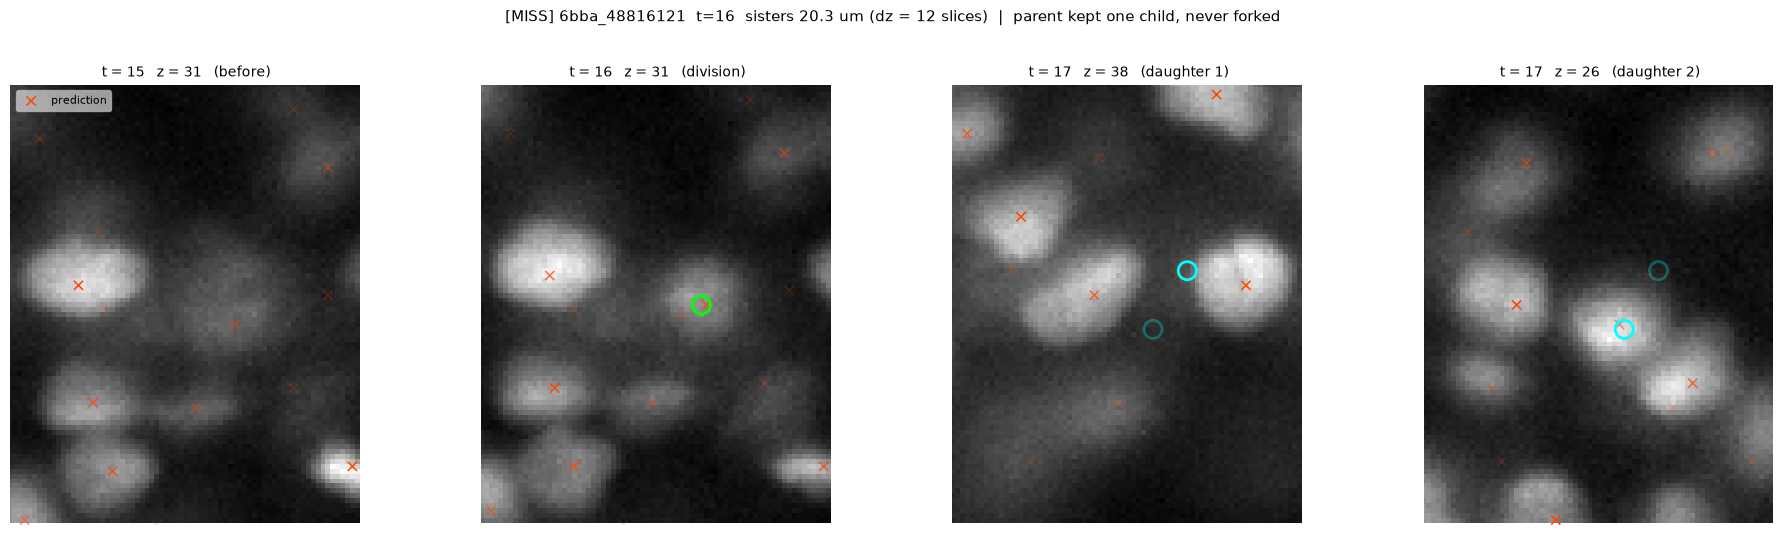

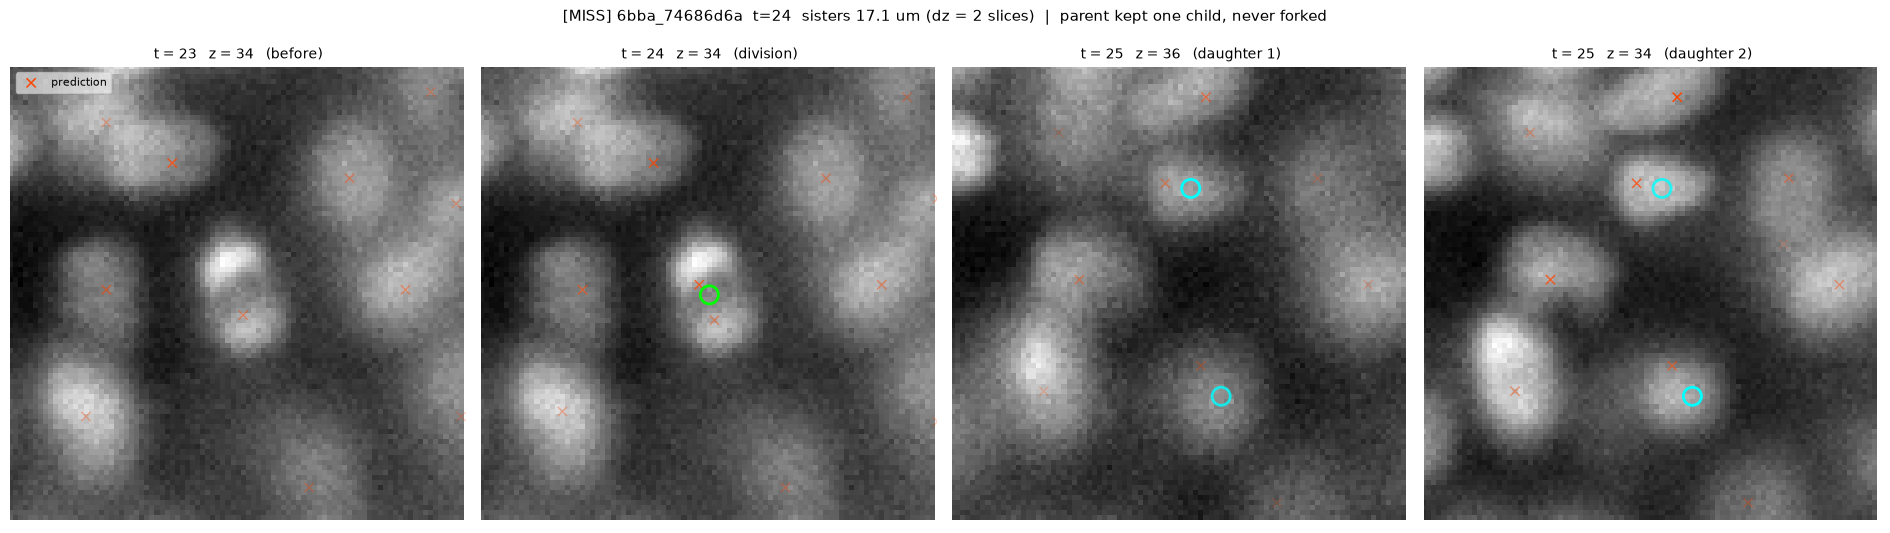

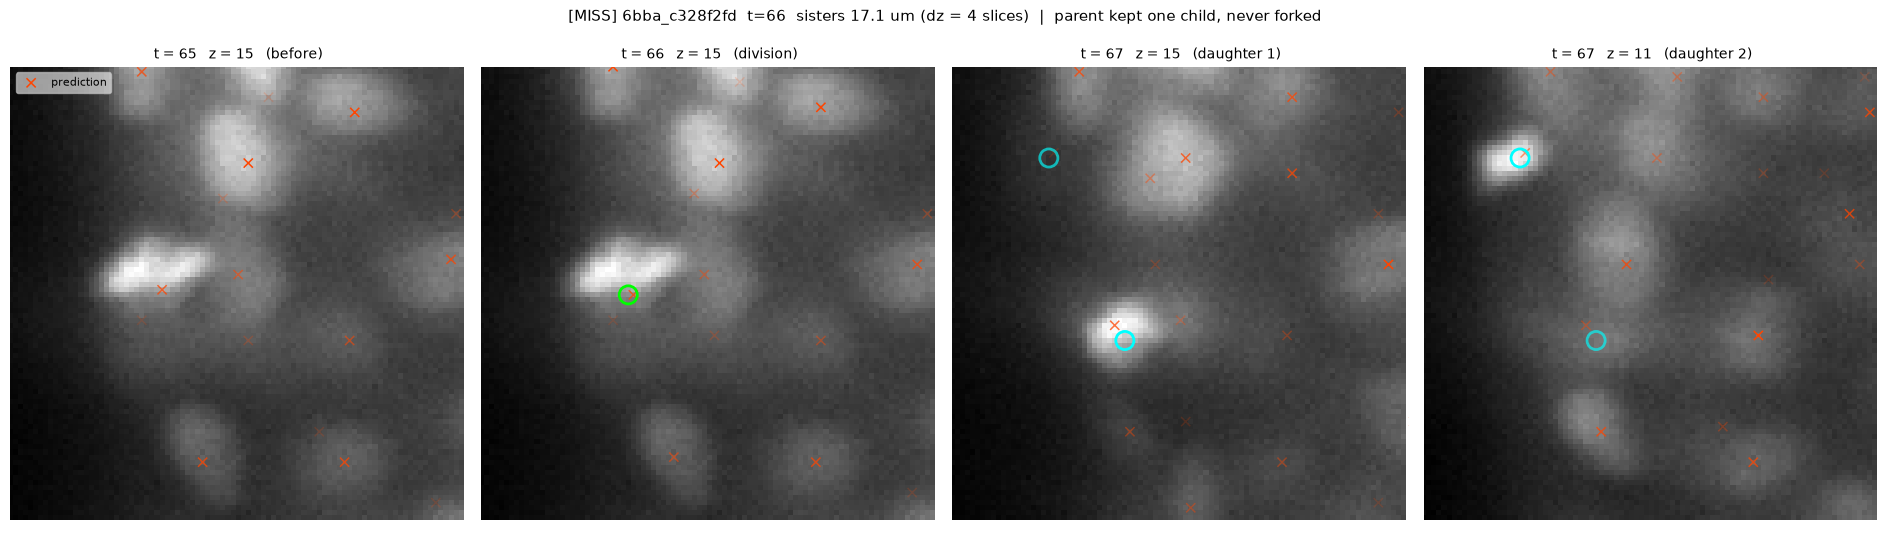

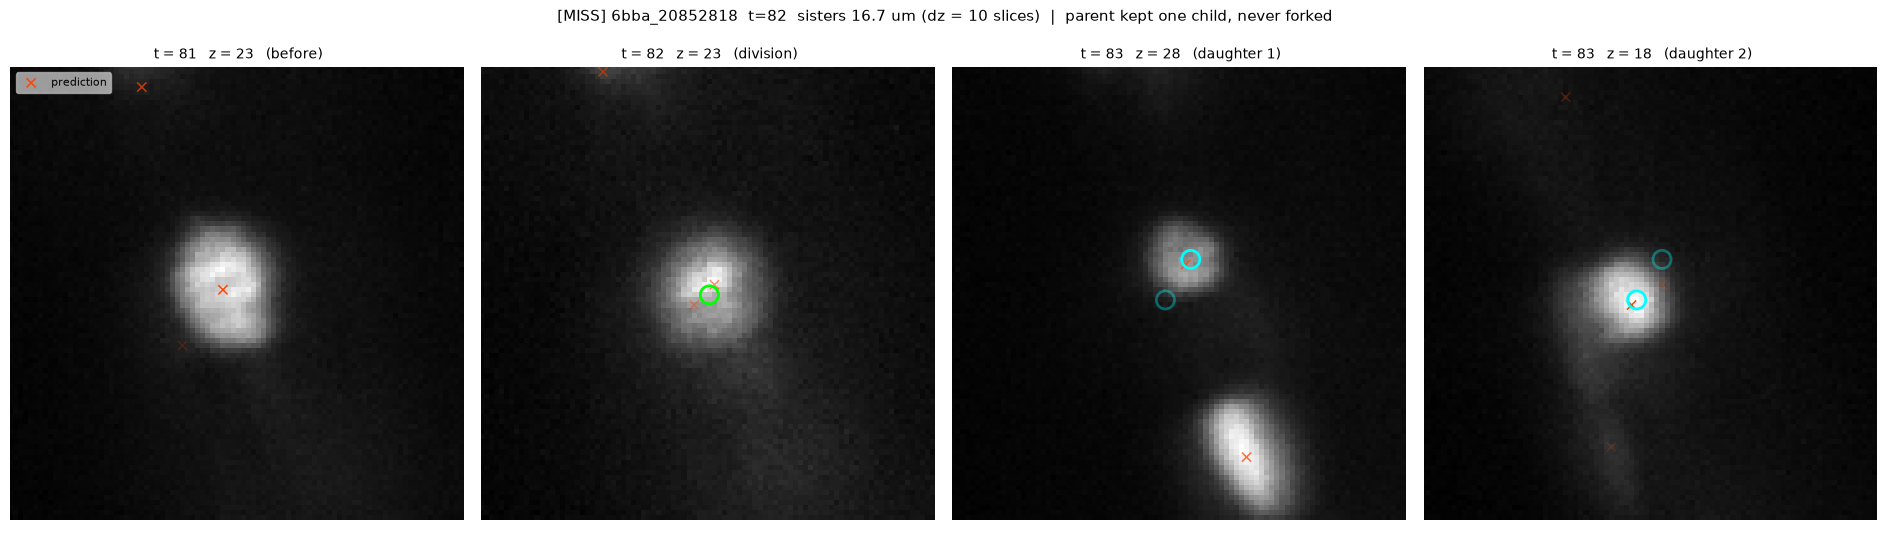

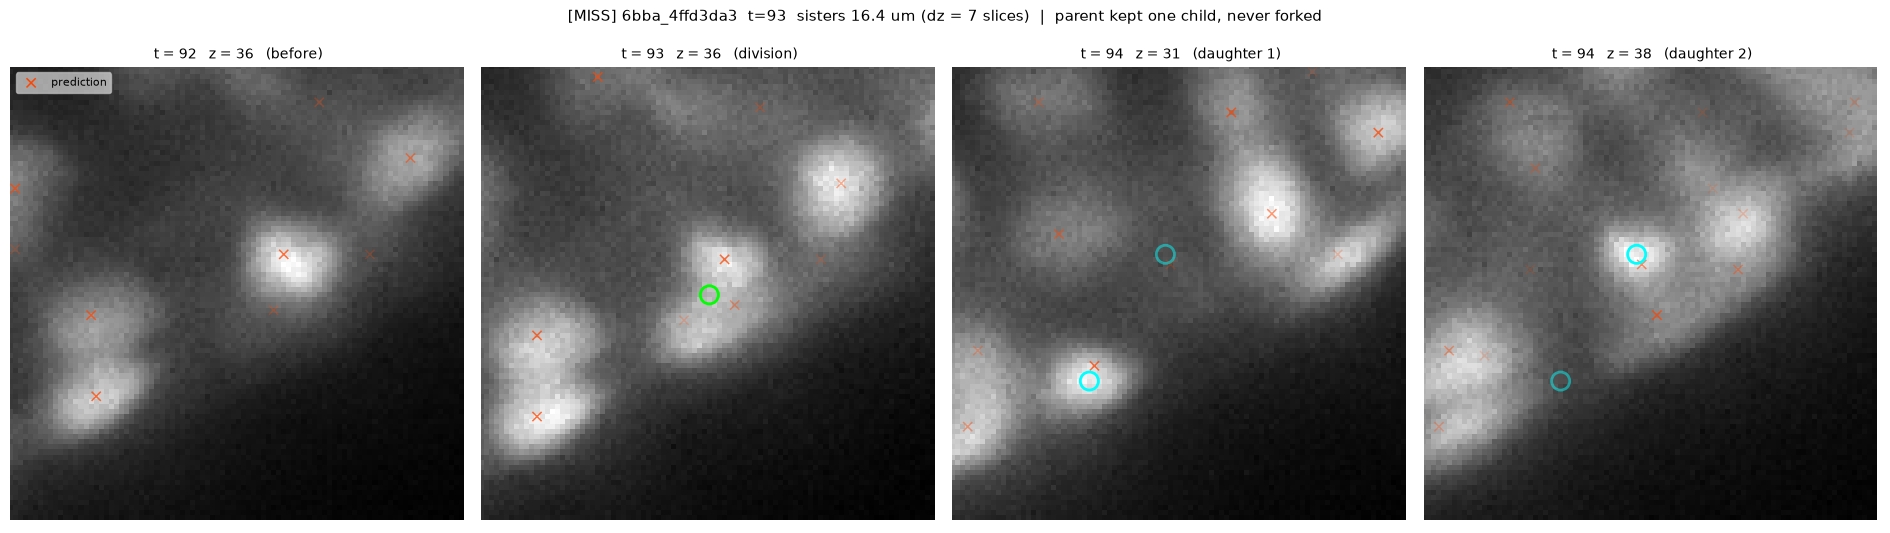

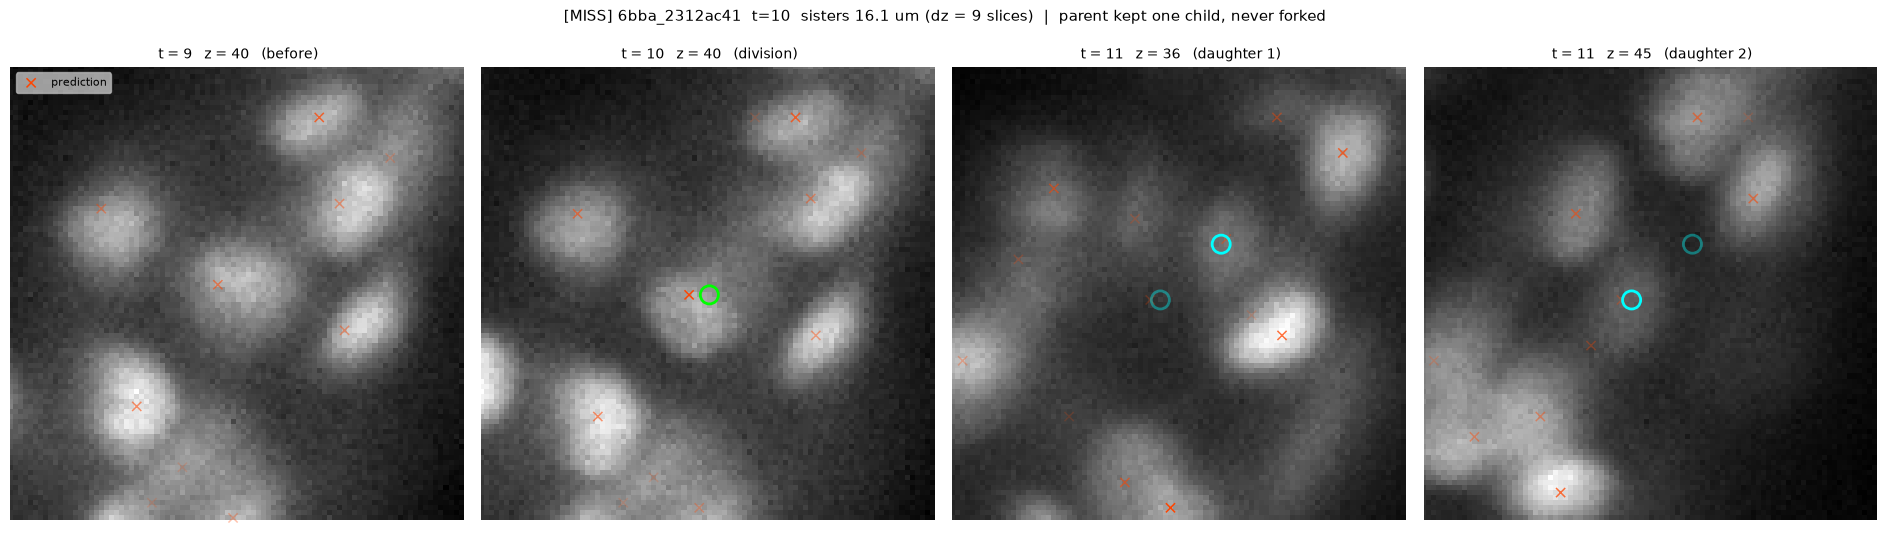

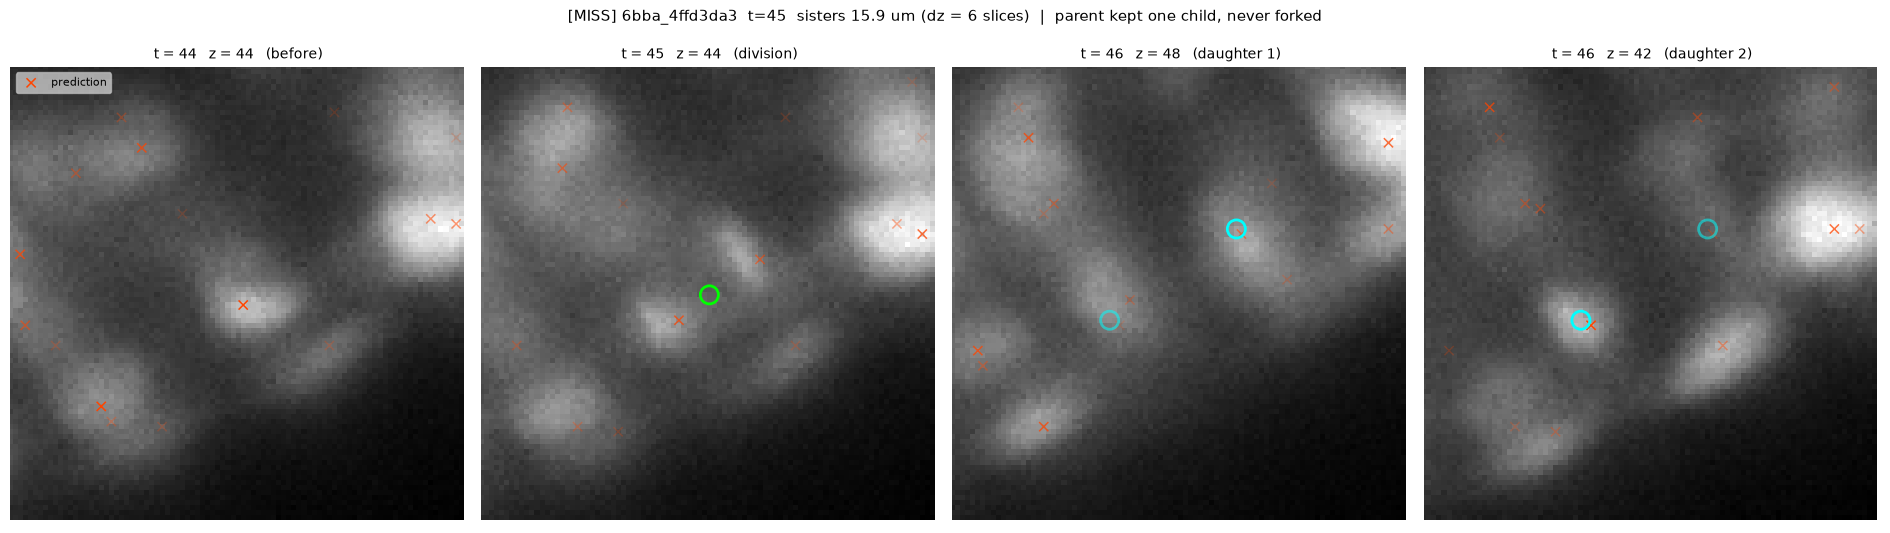

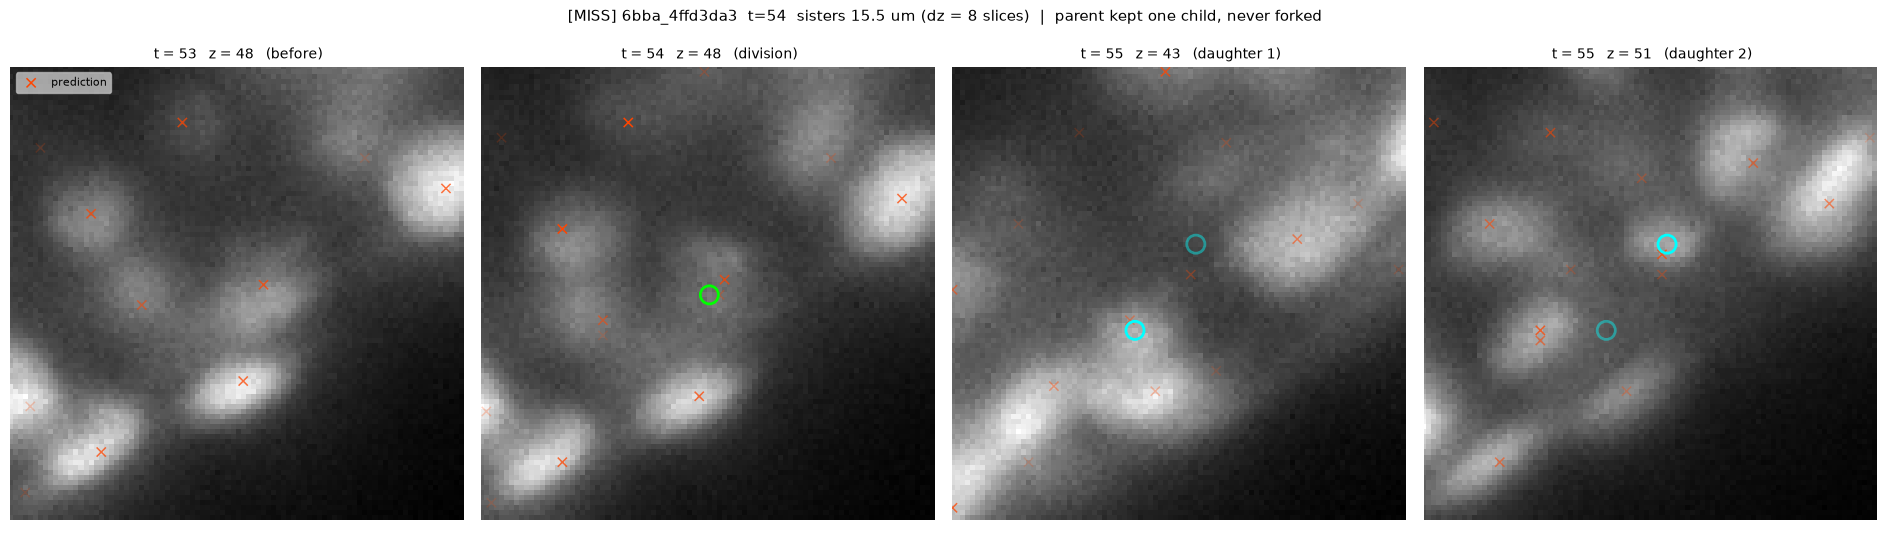

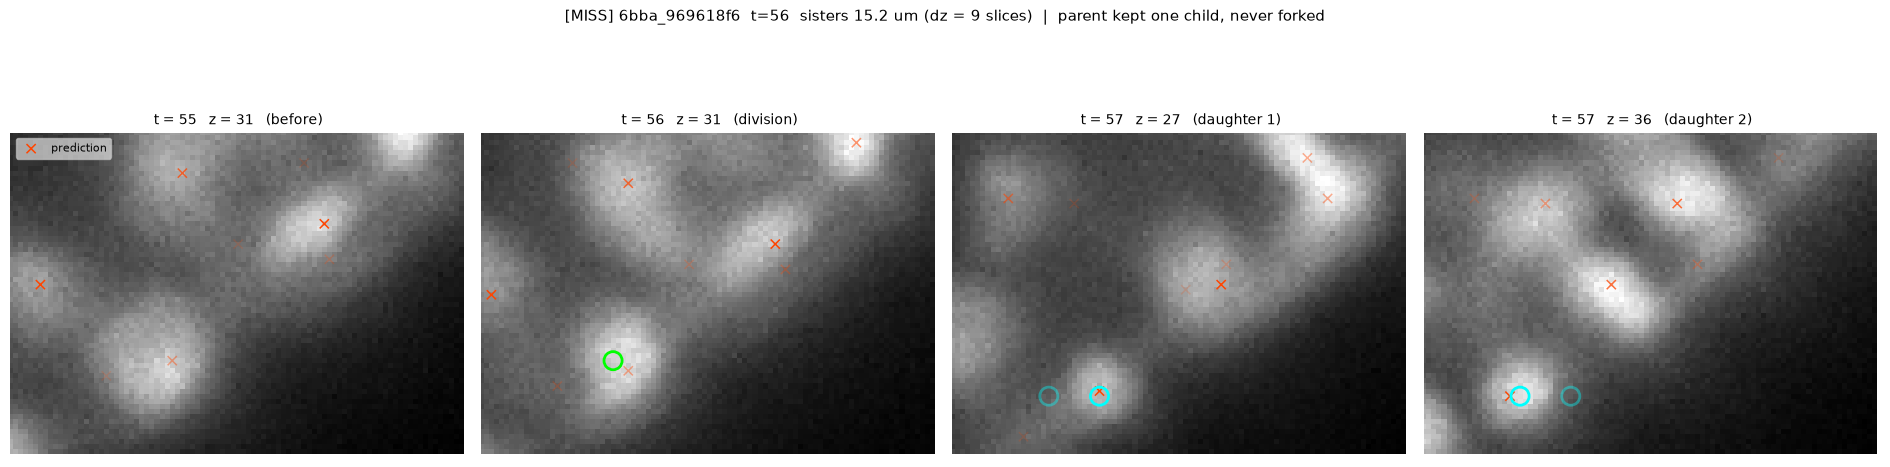

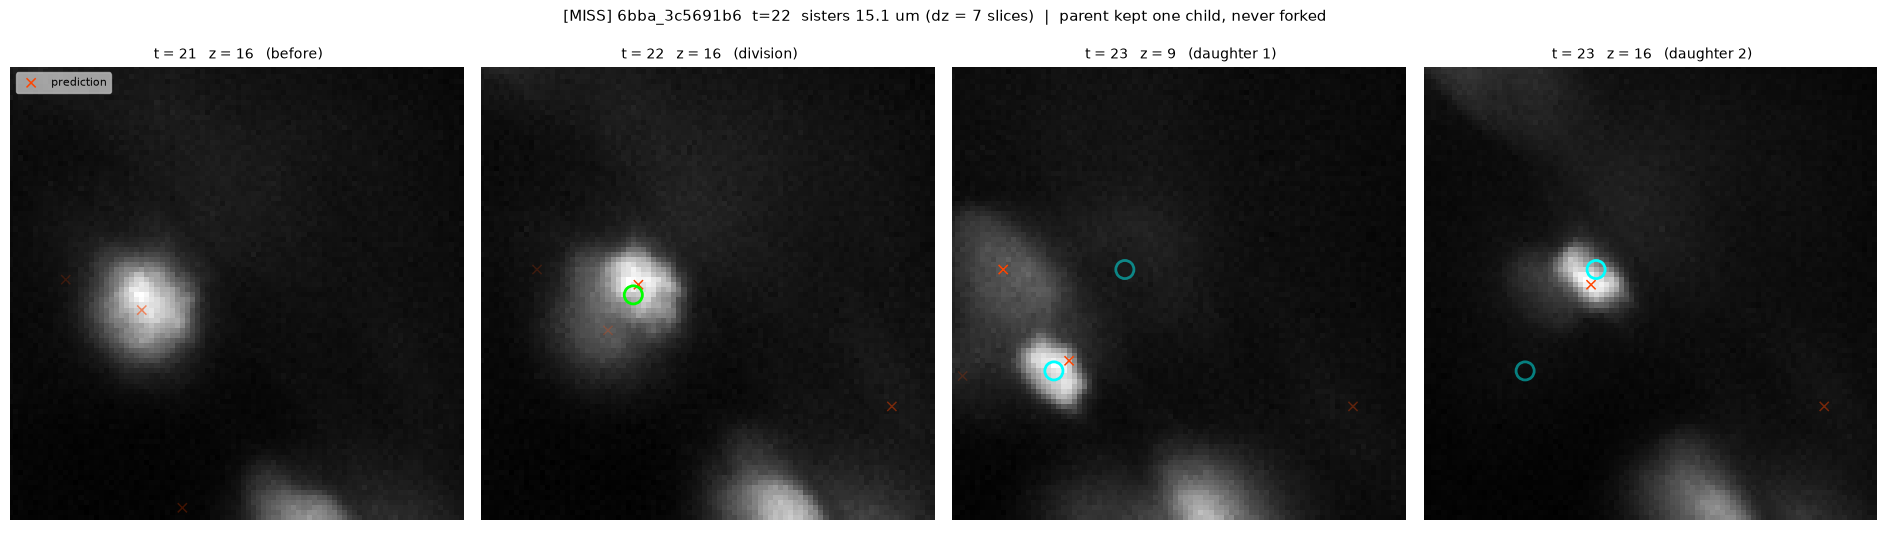

In [11]:
MAX_PLOTS = 10        # None = every division
ONLY = None             # e.g. "missed" / "recovered" / a `why` string / an embryo

view = divs
if ONLY == "missed":
    view = divs[~divs["recovered"]]
elif ONLY == "recovered":
    view = divs[divs["recovered"]]
elif ONLY in set(divs["why"]):
    view = divs[divs["why"] == ONLY]
elif ONLY in set(divs["embryo"]):
    view = divs[divs["embryo"] == ONLY]

# misses first, and within them the ones whose sisters are furthest apart --
# those are the ones geometry had the best chance on.
view = view.sort_values(["recovered", "sister_um"], ascending=[True, False])
print(f"plotting {len(view) if MAX_PLOTS is None else min(MAX_PLOTS, len(view))} of {len(view)}")

for _, row in (view if MAX_PLOTS is None else view.head(MAX_PLOTS)).iterrows():
    plot_division(row)

Done !